
# LearnLoop — Learning Analytics Exploration

## Project objective

LearnLoop is a learning-planning companion designed to help students managing multiple online courses organise their workload and decide what to study next.

This notebook explores the Open University Learning Analytics Dataset (OULAD) to understand student engagement, assessment behaviour and learning outcomes.

## Research questions

1. How does student engagement with online learning materials vary?
2. Is engagement associated with assessment performance?
3. How do assessment submission patterns relate to student outcomes?
4. Are there observable differences in learning behaviour across courses?

## Dataset

**Source:** Open University Learning Analytics Dataset (OULAD)

The dataset contains anonymised student information, course registrations, assessments and virtual learning environment interactions.

## Important limitation

OULAD is historical data from the Open University. It does not directly represent students managing multiple unrelated online courses or their available study hours.

The analysis will inform product hypotheses, not prove that LearnLoop's proposed features will work.

## Analysis approach

- Data inspection and quality checks
- Exploratory data analysis
- Student engagement analysis
- Assessment and performance analysis
- Product insights and recommendations


In [1]:

from pathlib import Path

# Locate the OULAD dataset folder
data_path = Path("../data/oulad")

# Check whether the folder exists
print("Dataset folder exists:", data_path.exists())

# List all CSV files
csv_files = list(data_path.glob("*.csv"))

print("\nNumber of CSV files found:", len(csv_files))

# Display file names and sizes
for file in sorted(csv_files):
    size_mb = file.stat().st_size / (1024 * 1024)
    print(f"{file.name}: {size_mb:.2f} MB")


Dataset folder exists: True

Number of CSV files found: 7
assessments.csv: 0.01 MB
courses.csv: 0.00 MB
studentAssessment.csv: 5.43 MB
studentInfo.csv: 3.30 MB
studentRegistration.csv: 1.08 MB
studentVle.csv: 432.81 MB
vle.csv: 0.26 MB


In [2]:

import pandas as pd

files_to_inspect = [
    "courses.csv",
    "assessments.csv",
    "studentInfo.csv",
    "studentRegistration.csv",
    "studentAssessment.csv",
    "vle.csv"
]

for filename in files_to_inspect:
    df = pd.read_csv(data_path / filename)
    print(f"\n{'='*50}")
    print(f"{filename} | Shape: {df.shape}")
    print("Columns:", list(df.columns))
    print(df.head(2).to_string(index=False))



courses.csv | Shape: (22, 3)
Columns: ['code_module', 'code_presentation', 'module_presentation_length']
code_module code_presentation  module_presentation_length
        AAA             2013J                         268
        AAA             2014J                         269

assessments.csv | Shape: (206, 6)
Columns: ['code_module', 'code_presentation', 'id_assessment', 'assessment_type', 'date', 'weight']
code_module code_presentation  id_assessment assessment_type date  weight
        AAA             2013J           1752             TMA   19    10.0
        AAA             2013J           1753             TMA   54    20.0

studentInfo.csv | Shape: (32593, 12)
Columns: ['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']
code_module code_presentation  id_student gender              region highest_education imd_band age_band  num_of_prev_attempts 

In [3]:

tables = [
    "studentInfo.csv",
    "studentRegistration.csv",
    "assessments.csv",
    "studentAssessment.csv",
    "vle.csv"
]

for filename in tables:
    df = pd.read_csv(data_path / filename)

    print(f"\n{filename} | Rows: {len(df):,}")
    print("Missing values:", df.isna().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

# Check the large interaction file without loading it fully
vle_sample = pd.read_csv(data_path / "studentVle.csv", nrows=5)
print("\nstudentVle columns:", list(vle_sample.columns))
print(vle_sample.to_string(index=False))



studentInfo.csv | Rows: 32,593
Missing values: 0
Duplicate rows: 0

studentRegistration.csv | Rows: 32,593
Missing values: 0
Duplicate rows: 0

assessments.csv | Rows: 206
Missing values: 0
Duplicate rows: 0

studentAssessment.csv | Rows: 173,912
Missing values: 0
Duplicate rows: 0

vle.csv | Rows: 6,364
Missing values: 0
Duplicate rows: 0

studentVle columns: ['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']
code_module code_presentation  id_student  id_site  date  sum_click
        AAA             2013J       28400   546652   -10          4
        AAA             2013J       28400   546652   -10          1
        AAA             2013J       28400   546652   -10          1
        AAA             2013J       28400   546614   -10         11
        AAA             2013J       28400   546714   -10          1


In [4]:

# Student outcome distribution
students = pd.read_csv(data_path / "studentInfo.csv")

print("Student outcomes:")
print(students["final_result"].value_counts())
print("\nOutcome percentages:")
print((students["final_result"].value_counts(normalize=True) * 100).round(2))

# Check special missing-value markers
vle = pd.read_csv(data_path / "vle.csv")

print("\nSpecial '?' values in VLE:")
print(vle[["week_from", "week_to"]].eq("?").sum())


Student outcomes:
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

Outcome percentages:
final_result
Pass           37.93
Withdrawn      31.16
Fail           21.64
Distinction     9.28
Name: proportion, dtype: float64

Special '?' values in VLE:
week_from    5243
week_to      5243
dtype: int64


In [5]:
keys = ["code_module", "code_presentation", "id_student"]
engagement_parts = []

for chunk in pd.read_csv(
    data_path / "studentVle.csv",
    usecols=keys + ["sum_click"],
    chunksize=500_000
):
    grouped = chunk.groupby(keys, as_index=False)["sum_click"].sum()
    engagement_parts.append(grouped)

engagement = (
    pd.concat(engagement_parts)
    .groupby(keys, as_index=False)["sum_click"]
    .sum()
)

analysis = students.merge(
    engagement,
    on=keys,
    how="left",
    validate="one_to_one"
)

result = analysis.groupby("final_result")["sum_click"].agg(
    ["count", "mean", "median"]
).round(2)

print(result)


              count     mean  median
final_result                        
Distinction    3024  2666.76  1896.0
Fail           6678   688.36   353.0
Pass          12358  1922.28  1343.0
Withdrawn      7168   444.82   221.5


In [6]:

coverage = analysis.groupby("final_result").agg(
    total_students=("id_student", "count"),
    students_with_activity=("sum_click", "count"),
    students_without_activity=("sum_click", lambda x: x.isna().sum())
)

coverage["activity_coverage_pct"] = (
    coverage["students_with_activity"] / coverage["total_students"] * 100
).round(2)

print(coverage)


              total_students  students_with_activity  \
final_result                                           
Distinction             3024                    3024   
Fail                    7052                    6678   
Pass                   12361                   12358   
Withdrawn              10156                    7168   

              students_without_activity  activity_coverage_pct  
final_result                                                    
Distinction                           0                 100.00  
Fail                                374                  94.70  
Pass                                  3                  99.98  
Withdrawn                          2988                  70.58  


In [7]:

registrations = pd.read_csv(data_path / "studentRegistration.csv")

check = analysis.merge(
    registrations,
    on=keys,
    how="left",
    validate="one_to_one"
)

withdrawn = check[check["final_result"] == "Withdrawn"]

print("Withdrawn students by activity status:")
print(
    withdrawn.assign(
        activity_status=withdrawn["sum_click"].isna().map({
            True: "No recorded activity",
            False: "Has recorded activity"
        })
    ).groupby("activity_status")["date_unregistration"]
    .agg(["count", lambda x: x.eq("?").sum()])
)


Withdrawn students by activity status:
                       count  <lambda_0>
activity_status                         
Has recorded activity   7168          74
No recorded activity    2988          19


In [8]:

withdrawn["unregistration_day"] = pd.to_numeric(
    withdrawn["date_unregistration"].replace("?", pd.NA)
)

withdrawn["activity_status"] = withdrawn["sum_click"].isna().map({
    True: "No recorded activity",
    False: "Has recorded activity"
})

print(
    withdrawn.groupby("activity_status")["unregistration_day"]
    .agg(["count", "median", "mean", "min", "max"])
    .round(2)
)


                       count  median   mean    min    max
activity_status                                          
Has recorded activity   7094    68.0  82.72 -365.0  444.0
No recorded activity    2969   -18.0 -28.89 -317.0  226.0


In [9]:

weekly_parts = []

for chunk in pd.read_csv(
    data_path / "studentVle.csv",
    usecols=keys + ["date", "sum_click"],
    chunksize=500_000
):
    chunk = chunk[chunk["date"] >= 0].copy()
    chunk["week"] = chunk["date"] // 7

    chunk = chunk.merge(
        students[keys + ["final_result"]],
        on=keys,
        how="left"
    )

    weekly = chunk.groupby(
        ["final_result", "week"]
    )["sum_click"].sum().reset_index()

    weekly_parts.append(weekly)

weekly_engagement = (
    pd.concat(weekly_parts)
    .groupby(["final_result", "week"])["sum_click"]
    .sum()
    .reset_index()
)

outcome_counts = students["final_result"].value_counts()

weekly_engagement["clicks_per_student"] = (
    weekly_engagement["sum_click"] /
    weekly_engagement["final_result"].map(outcome_counts)
)

print(
    weekly_engagement.pivot(
        index="week",
        columns="final_result",
        values="clicks_per_student"
    ).round(2).to_string()
)


final_result  Distinction   Fail   Pass  Withdrawn
week                                              
0                  113.60  44.70  81.10      34.65
1                  101.49  38.62  73.90      30.02
2                  117.88  55.73  92.43      40.87
3                   94.25  37.37  69.74      24.92
4                   87.40  32.06  64.99      20.83
5                   73.69  24.73  55.00      14.95
6                   82.20  27.67  61.34      14.63
7                   78.05  26.10  58.32      14.43
8                   64.23  16.10  42.87       9.09
9                   71.40  20.11  48.06      10.85
10                  48.66  10.70  30.35       4.84
11                  38.95   9.99  27.99       4.31
12                  55.01  14.92  40.83       5.47
13                  67.97  15.63  49.92       5.87
14                  63.03  13.02  43.59       4.94
15                  64.24  12.17  43.26       4.22
16                  65.33  12.47  44.90       4.05
17                  68.92  13.0

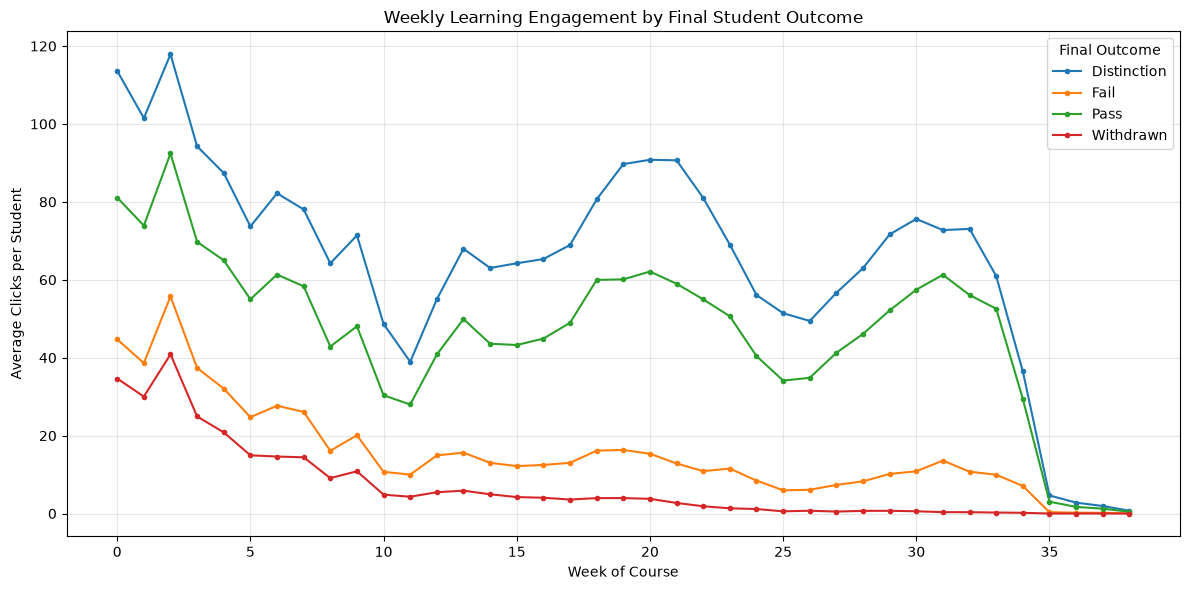

In [10]:

import matplotlib.pyplot as plt

plot_data = (
    weekly_engagement
    .pivot(index="week", columns="final_result",
           values="clicks_per_student")
    .fillna(0)
)

plot_data.plot(figsize=(12, 6), marker="o", markersize=3)

plt.title("Weekly Learning Engagement by Final Student Outcome")
plt.xlabel("Week of Course")
plt.ylabel("Average Clicks per Student")
plt.legend(title="Final Outcome")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:

assessments = pd.read_csv(data_path / "assessments.csv")
submissions = pd.read_csv(data_path / "studentAssessment.csv")

assessment_data = (
    submissions
    .merge(
        assessments,
        on="id_assessment",
        how="left"
    )
    .merge(
        students,
        on=["id_student", "code_module", "code_presentation"],
        how="left"
    )
)


assessment_data["score"] = pd.to_numeric(
    assessment_data["score"],
    errors="coerce"
)

print(
    assessment_data.groupby("final_result")["score"]
    .agg(["count", "mean", "median"])
    .round(2)
)



               count   mean  median
final_result                       
Distinction    26330  88.68    91.0
Fail           28399  64.69    66.0
Pass          105987  76.77    79.0
Withdrawn      13023  66.08    70.0


In [12]:

assessment_data["date_submitted"] = pd.to_numeric(
    assessment_data["date_submitted"],
    errors="coerce"
)

assessment_data["date"] = pd.to_numeric(
    assessment_data["date"],
    errors="coerce"
)

assessment_data["days_late"] = (
    assessment_data["date_submitted"] - assessment_data["date"]
)

print(
    assessment_data.groupby("final_result")["days_late"]
    .agg(["count", "mean", "median"])
    .round(2)
)


               count   mean  median
final_result                       
Distinction    25720 -22.80    -2.0
Fail           28069 -11.79     0.0
Pass          104163 -17.07    -1.0
Withdrawn      13095 -11.74     0.0


In [13]:

assessment_data["is_late"] = (
    assessment_data["days_late"] > 0
)

late_submission_rate = (
    assessment_data.groupby("final_result")["is_late"]
    .mean()
    .mul(100)
    .round(2)
)

print(late_submission_rate)


final_result
Distinction    22.62
Fail           37.18
Pass           25.84
Withdrawn      41.08
Name: is_late, dtype: float64



## OULAD Data Analysis — Initial Findings

### 1. Student outcomes
- Pass: 37.93%
- Distinction: 9.28%
- Fail: 21.64%
- Withdrawn: 31.16%

### 2. Engagement patterns
- Distinction students averaged 2,666.76 VLE clicks.
- Pass students averaged 1,922.28 clicks.
- Fail students averaged 688.36 clicks.
- Withdrawn students averaged 444.82 clicks.
- Students without recorded VLE activity were disproportionately represented among withdrawn students.

### 3. Withdrawal timing
- Withdrawn students with no recorded activity had a median unregistration day of -18.
- Those with recorded activity had a median unregistration day of 68.
- This suggests early non-engagement and later disengagement may be different patterns.

### 4. Assessment performance
- Mean assessment scores ranged from 64.69 for Fail students to 88.68 for Distinction students.
- These are submission-level averages, not student-level averages.

### 5. Submission timing
- Late submission rate:
  - Distinction: 22.62%
  - Pass: 25.84%
  - Fail: 37.18%
  - Withdrawn: 41.08%

### Product opportunities to investigate
1. Detect declining engagement early.
2. Identify repeated late submissions and approaching deadline risks.
3. Help learners reprioritise tasks based on deadlines and progress.

### Limitations
- OULAD is historical data from a single university, not multiple learning platforms.
- Clicks measure recorded platform activity, not actual learning.
- Associations do not establish causation.
- The dataset does not contain learners' available study hours.


In [14]:

student_lateness = (
    assessment_data
    .groupby(keys)
    .agg(
        total_submissions=("is_late", "count"),
        late_submissions=("is_late", "sum"),
        late_rate=("is_late", "mean")
    )
    .reset_index()
)

student_lateness = student_lateness.merge(
    students[keys + ["final_result"]],
    on=keys,
    how="left"
)

student_lateness["late_rate"] *= 100

print(
    student_lateness.groupby("final_result")["late_rate"]
    .agg(["count", "mean", "median"])
    .round(2)
)


              count   mean  median
final_result                      
Distinction    3024  21.89    8.33
Fail           5768  35.65   33.33
Pass          12358  24.71   14.29
Withdrawn      4693  41.35   36.36


In [15]:

from scipy.stats import kruskal

groups = [
    group["late_rate"].dropna()
    for _, group in student_lateness.groupby("final_result")
]

statistic, p_value = kruskal(*groups)

print("Kruskal-Wallis statistic:", round(statistic, 3))
print("P-value:", p_value)


Kruskal-Wallis statistic: 736.063
P-value: 3.1769931524007996e-159



### 6. Student-level late submission analysis

Each student was assigned an individual late-submission rate.

| Outcome | Mean late rate | Median late rate |
|---|---:|---:|
| Distinction | 21.89% | 8.33% |
| Pass | 24.71% | 14.29% |
| Fail | 35.65% | 33.33% |
| Withdrawn | 41.35% | 36.36% |

A Kruskal–Wallis test found statistically significant differences across outcome groups (H = 736.063, p < 0.001).

**Interpretation:** Late-submission behaviour is associated with final student outcomes. Further pairwise testing is needed to identify which groups differ.

**Limitation:** Only students with at least one recorded assessment submission were included.


In [16]:

import scikit_posthocs as sp

pairwise_results = sp.posthoc_dunn(
    student_lateness,
    val_col="late_rate",
    group_col="final_result",
    p_adjust="bonferroni"
)

print(pairwise_results.round(6))


             Distinction      Fail  Pass  Withdrawn
Distinction          1.0  0.000000   0.0   0.000000
Fail                 0.0  1.000000   0.0   0.000306
Pass                 0.0  0.000000   1.0   0.000000
Withdrawn            0.0  0.000306   0.0   1.000000



### 7. Pairwise comparison of late-submission behaviour

A Dunn post-hoc test with Bonferroni correction was conducted following the Kruskal–Wallis test.

All six pairwise comparisons between Distinction, Pass, Fail and Withdrawn groups were statistically significant (adjusted p < 0.001).

**Interpretation:** Each outcome group showed a statistically different distribution of student-level late-submission rates.

**Product implication:** Repeated late submissions may be worth investigating as an early deadline-risk signal in LearnLoop.

**Limitation:** Statistical association does not establish that late submissions cause poor academic outcomes.


In [17]:

early_engagement = weekly_engagement[
    weekly_engagement["week"] < 10
]

early_pivot = early_engagement.pivot(
    index="week",
    columns="final_result",
    values="clicks_per_student"
)

print(early_pivot.round(2))


final_result  Distinction   Fail   Pass  Withdrawn
week                                              
0                  113.60  44.70  81.10      34.65
1                  101.49  38.62  73.90      30.02
2                  117.88  55.73  92.43      40.87
3                   94.25  37.37  69.74      24.92
4                   87.40  32.06  64.99      20.83
5                   73.69  24.73  55.00      14.95
6                   82.20  27.67  61.34      14.63
7                   78.05  26.10  58.32      14.43
8                   64.23  16.10  42.87       9.09
9                   71.40  20.11  48.06      10.85


In [18]:

early_pivot = early_pivot.sort_index()

weekly_change = early_pivot.pct_change() * 100

print(weekly_change.round(2))


final_result  Distinction   Fail   Pass  Withdrawn
week                                              
0                     NaN    NaN    NaN        NaN
1                  -10.66 -13.59  -8.87     -13.36
2                   16.15  44.30  25.07      36.15
3                  -20.04 -32.95 -24.55     -39.04
4                   -7.27 -14.20  -6.80     -16.40
5                  -15.68 -22.85 -15.38     -28.25
6                   11.55  11.87  11.53      -2.11
7                   -5.05  -5.66  -4.93      -1.35
8                  -17.71 -38.31 -26.48     -37.00
9                   11.16  24.85  12.10      19.30



### 8. Early engagement trend analysis

Weekly average VLE clicks were compared across students grouped by their eventual final outcomes.

During the first 10 weeks:
- Distinction students averaged 113.60 clicks in Week 0 and 71.40 in Week 9.
- Pass students averaged 81.10 and 48.06.
- Fail students averaged 44.70 and 20.11.
- Withdrawn students averaged 34.65 and 10.85.

Withdrawn students showed the largest decline between Week 0 and Week 9 (68.7%).

Week-on-week engagement was not consistently declining. All outcome groups experienced fluctuations, including increases in some weeks.

**Interpretation:** Early engagement differences may provide useful context for understanding student disengagement.

**Product opportunity:** Investigate a personalised engagement-risk indicator that combines changes in activity with assessment and deadline behaviour.

**Limitations:**
- The analysis groups students by their eventual outcome.
- It does not establish individual-level predictive accuracy.
- VLE clicks are an imperfect proxy for actual learning.
- The analysis aggregates multiple courses and presentations.


In [ ]:

early_parts = []

for chunk in pd.read_csv(
    data_path / "studentVle.csv",
    usecols=keys + ["date", "sum_click"],
    chunksize=500_000
):
    chunk = chunk[
        (chunk["date"] >= 0) &
        (chunk["date"] < 28)
    ]

    grouped = (
        chunk.groupby(keys)["sum_click"]
        .sum()
        .reset_index()
    )

    early_parts.append(grouped)

early_student_activity = (
    pd.concat(early_parts)
    .groupby(keys)["sum_click"]
    .sum()
    .reset_index(name="early_clicks")
)

early_student_activity = students[
    keys + ["final_result"]
].merge(
    early_student_activity,
    on=keys,
    how="left"
)

early_student_activity["early_clicks"] = (
    early_student_activity["early_clicks"].fillna(0)
)

print(
    early_student_activity.groupby("final_result")["early_clicks"]
    .agg(["count", "mean", "median"])
    .round(2)
)


In [ ]:

zero_activity = (
    early_student_activity
    .assign(
        zero_clicks=lambda df: df["early_clicks"] == 0
    )
    .groupby("final_result")["zero_clicks"]
    .agg(["count", "sum", "mean"])
)

zero_activity["percentage"] = (
    zero_activity["mean"] * 100
).round(2)

print(zero_activity[["count", "sum", "percentage"]])


              count   sum  percentage
final_result                         
Distinction    3024    30        0.99
Fail           7052   715       10.14
Pass          12361   202        1.63
Withdrawn     10156  3760       37.02



### 9. Zero early-engagement analysis

Students with no recorded VLE clicks during the first 28 days were compared across final outcomes.

| Outcome | Students with zero clicks | Percentage |
|---|---:|---:|
| Distinction | 30 | 0.99% |
| Pass | 202 | 1.63% |
| Fail | 715 | 10.14% |
| Withdrawn | 3,760 | 37.02% |

**Key finding:** 37.02% of students who eventually withdrew had no recorded VLE activity during their first 28 days, compared with 1.63% of students who passed.

**Product opportunity:**
1. An onboarding intervention for students who have not started engaging.
2. A re-engagement intervention for students whose activity declines after starting.

**Limitation:** This is a retrospective association, not a validated prediction model. Zero recorded clicks do not necessarily mean zero learning activity.


In [ ]:

early_student_activity["activity_status"] = (
    early_student_activity["early_clicks"]
    .eq(0)
    .map({
        True: "Zero activity",
        False: "Some activity"
    })
)

outcome_by_activity = pd.crosstab(
    early_student_activity["activity_status"],
    early_student_activity["final_result"],
    normalize="index"
) * 100

print(outcome_by_activity.round(2))


final_result     Distinction   Fail   Pass  Withdrawn
activity_status                                      
Some activity          10.74  22.72  43.60      22.94
Zero activity           0.64  15.19   4.29      79.88


In [ ]:

withdrawal_summary = (
    early_student_activity
    .groupby("activity_status")
    .agg(
        total_students=("id_student", "count"),
        withdrawn_students=(
            "final_result",
            lambda x: (x == "Withdrawn").sum()
        )
    )
)

withdrawal_summary["withdrawal_rate"] = (
    withdrawal_summary["withdrawn_students"]
    / withdrawal_summary["total_students"] * 100
).round(2)

print(withdrawal_summary)


                 total_students  withdrawn_students  withdrawal_rate
activity_status                                                     
Some activity             27886                6396            22.94
Zero activity              4707                3760            79.88


In [ ]:

course_activity = (
    early_student_activity
    .groupby(["code_module", "activity_status"])
    .agg(
        total_students=("id_student", "count"),
        withdrawn_students=(
            "final_result",
            lambda x: (x == "Withdrawn").sum()
        )
    )
    .reset_index()
)

course_activity["withdrawal_rate"] = (
    course_activity["withdrawn_students"]
    / course_activity["total_students"] * 100
).round(2)

course_comparison = course_activity.pivot(
    index="code_module",
    columns="activity_status",
    values="withdrawal_rate"
)

course_comparison["rate_difference"] = (
    course_comparison["Zero activity"]
    - course_comparison["Some activity"]
)

print(course_comparison.round(2))


activity_status  Some activity  Zero activity  rate_difference
code_module                                                   
AAA                      14.50          87.50            73.00
BBB                      17.59          80.89            63.30
CCC                      36.87          91.49            54.62
DDD                      28.73          86.15            57.42
EEE                      16.94          80.51            63.57
FFF                      23.10          89.45            66.35
GGG                       8.37          26.85            18.48



### 10. Course-level validation of early inactivity

The relationship between zero recorded VLE activity during the first 28 days and eventual withdrawal was examined across all seven course modules.

Zero-activity students had a higher withdrawal rate in every course.

The difference ranged from 18.48 percentage points in GGG to 73.00 percentage points in AAA.

**Key finding:** The relationship between early inactivity and withdrawal appears across multiple courses, although its strength varies by course.

**Product implication:** LearnLoop could explore course-aware onboarding and early-engagement interventions rather than applying identical prompts to every learner.

**Limitation:** This is observational, retrospective data. It does not establish that inactivity causes withdrawal or that an intervention would prevent it.
